<a href="https://colab.research.google.com/github/gabp20/Final-project-gabp20/blob/main/Copy_of_02_p53_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 Notebook 02 — Does your gene respond to p53 loss?

**Produces:** a landscape, two statistical comparisons, one figure, and
the assembled answer.

---

> **This notebook does not need Notebook 01.** Its data file arrives
> already clean. If Notebook 01 defeated you, start here — you lose
> nothing.

Four functions, each with its own check:

| | question | why you ask it |
|---|---|---|
| `expression_landscape` | where is my gene expressed across cancers? | is it even switched on in my tumour type? |
| `compare_groups` | tumour vs normal? mutant vs wild-type? | the actual hypothesis test |
| `plot_comparison` | what does it look like on one axis? | the figure a paper would print |
| `run_analysis` | all of it, as one answer | wiring it together |

> ### ⚠️ Run every cell, in order, from the top
>
> Your functions only exist once you have **run** the cell that defines
> them. If you edit a function, you must re-run its cell or Python
> carries on using the old version — which is the single most confusing
> bug in notebook work.
>
> If anything stops making sense, use **Runtime → Restart and run all**
> (Colab) or **Kernel → Restart & Run All** (VS Code) and start clean.

## Run this first

> ✏️ **Before you run the cell below, add your Sussex username.**
>
> Scroll to the **bottom** of the cell — **line 66 of 77** —
> and type your Sussex username (the start of your Sussex email, the
> one you log in with) between the quotes:
>
> ```python
> STUDENT_ID = "ab123"   # <-- your Sussex username
> ```
>
> Then run the cell (**Shift + Enter**). It prints your gene and cancer
> type. Change nothing else in that cell.
>
> 💡 To see line numbers in Colab: **Tools → Settings → Editor → Show
> line numbers**.

In [47]:
# Run this first. It downloads your data and sets up the self-checks.
import hashlib
import json
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

DATA_URL = "https://raw.githubusercontent.com/HocheggerLab/tcga-capstone-2026/main/data/"

def fetch(filename):
    """Return a local data path, downloading it in Colab if needed."""
    repo_path = Path("data") / filename
    working_path = Path(filename)

    if repo_path.exists():                   # running from the repo
        return repo_path
    if not working_path.exists():            # running in Colab
        urllib.request.urlretrieve(DATA_URL + filename, working_path)
    return working_path


def my_variant(student_id):
    """Look up your gene and cancer type from your Sussex username."""
    number = str(student_id).strip().lower()
    if not number:
        raise ValueError("Type your Sussex username into "
                         "STUDENT_ID, then run this cell again.")
    key = hashlib.pbkdf2_hmac("sha256", number.encode(), b'tcga-capstone-2026',
                              2_000_000).hex()[:16]
    lookup = json.loads(Path(fetch("variant_lookup.json")).read_text())
    if key not in lookup:
        raise ValueError(f"{number} is not on the class list. Check it "
                         "against Canvas; if it is right, email the convenor.")
    gene, cancer_type = lookup[key]
    print(f"{number}: your gene is {gene}, your cancer type is {cancer_type}")
    return gene, cancer_type


def run_checks(checks):
    """Run a dict of {description: test} and report what passed.

    Each test is a zero-argument function returning True or False. A
    test that raises is reported rather than stopping the notebook, so
    you always see the full picture.
    """
    passed = 0
    for description, test in checks.items():
        try:
            ok = bool(test())
        except Exception as exc:
            print(f"\u274c {description}")
            print(f"     raised {type(exc).__name__}: {exc}")
            continue
        print(f"{'\u2705' if ok else '\u274c'} {description}")
        passed += ok
    print()
    print(f"{passed} of {len(checks)} checks passed")
    if passed < len(checks):
        print("Keep going - fix the crosses and run this cell again.")


STUDENT_ID = "gabp20"   # <-- your Sussex username, e.g. "ab123"

GENE, CANCER_TYPE = my_variant(STUDENT_ID)

MY_EXPRESSION = fetch(f"expression_{GENE}_{CANCER_TYPE}.csv")
EXAMPLE_EXPRESSION = fetch("expression_example.csv")

expr = pd.read_csv(MY_EXPRESSION)
example = pd.read_csv(EXAMPLE_EXPRESSION)

print(f"my data:        {len(expr):5d} rows - {GENE} in {CANCER_TYPE}")
print(f"worked example: {len(example):5d} rows - CDKN1A in BRCA")

gabp20: your gene is AEN, your cancer type is STAD
my data:         4930 rows - AEN in STAD
worked example:  4935 rows - CDKN1A in BRCA


## What is in this file

One row per sample, for one gene — yours.

| column | meaning |
|---|---|
| `sample_id`, `patient_id` | who this measurement came from |
| `cancer_type` | tumour type, as a 4-letter TCGA code |
| `group` | `tumour` or `normal` |
| `tp53_status` | `MUT` or `WT` — **already worked out for you** |
| `tp53_cn` | copy number of *TP53* (for the extension) |
| `gene_cn` | copy number of *your* gene (for the extension) |
| `log2_tpm` | **the expression measurement** |

### ⚠️ Two things you must not get wrong

**`log2_tpm` is already on a log2 scale** — it is `log2(TPM + 0.001)`.
Do **not** apply `np.log2` to it. Because it is already logged, a "fold
change" here is a **difference** of medians, not a ratio.

**`tp53_status` is blank for some tumours.** Not every patient had their
DNA sequenced. Those are *unknown*, not wild-type — treat them as
wild-type and you quietly dilute your own result. Drop them.

In [48]:
# DEMO - look before you leap
print(expr.groupby("group").size(), "\n")
print(expr[expr["group"] == "tumour"].tp53_status.value_counts(dropna=False), "\n")
print("log2_tpm range:", round(expr.log2_tpm.min(), 2), "to", round(expr.log2_tpm.max(), 2))

group
normal     174
tumour    4756
dtype: int64 

tp53_status
WT     2349
MUT    2013
NaN     394
Name: count, dtype: int64 

log2_tpm range: -9.97 to 6.11


---

## Task 2 — `expression_landscape`

**Question:** how does your gene's expression vary across cancer types?

This is context. Before testing anything you want to know whether your
gene is switched on at all in your tumour type, or whether you are about
to run statistics on noise.

**Takes** `expr` — the tidy expression table.

**Returns** a DataFrame of **tumour samples only**, one row per cancer
type:

```
cancer_type, n, median_log2tpm
```

Sorted by `median_log2tpm`, **highest first**, index reset.

In [49]:
# Keeping tumour samples
tumours = expr[expr["group"] == "tumour"] # select group column keep only those equal to tumour

# Count of tumour samples in each cancer type
counts = tumours.groupby("cancer_type").size() # groups cancer types and counts the rows per group

# median expression of each cancer type
median_log2tpm = tumours.groupby("cancer_type")["log2_tpm"].median() # seperatly take median of cancer_types

# Create two columns for n and median_log2tpm
summary = pd.DataFrame({"n": counts, "median_log2tpm": median_log2tpm})
summary = summary.sort_values(by="median_log2tpm", ascending = False) # sort by highest median_log2tpm first
summary = summary.reset_index() # resetting summary adds cancer_type to our table and solidifies index
summary

,cancer_type,n,median_log2tpm
0,COAD,288,4.04795
1,GBM,153,3.99650
2,KICH,66,3.65715
3,ESCA,181,3.62300
4,STAD,414,3.56995
5,PAAD,178,3.51675
6,LUSC,498,3.50730
7,PRAD,495,3.35910
8,BRCA,1092,3.33210
9,LUAD,513,3.27520


In [50]:
def expression_landscape(expr):
    """Summarise the tumour gene expression across all cancer types.

    Args:
        expr: the tidy expression of the DataFrame.

    Returns:
        pd.DataFrame: cancer_type(one row per type), n(tumour sample count), median_log2tpm(median expression).

    Ordered from highest median expression to the lowest and index was reset.
    The table is filtered to contain only the tumour sample group.
    """

    # Keeping tumour samples
    tumours = expr[expr["group"] == "tumour"] # select group column keep only those equal to tumour

    # Count of tumour samples in each cancer type
    counts = tumours.groupby("cancer_type").size() # groups cancer types and counts the rows per group

    # median expression of each cancer type
    median_log2tpm = tumours.groupby("cancer_type")["log2_tpm"].median() # separately take median of cancer_types

    # Create two columns for n and median_log2tpm
    summary = pd.DataFrame({"n": counts, "median_log2tpm": median_log2tpm})
    summary = summary.sort_values(by="median_log2tpm", ascending = False) # sort by highest median_log2tpm first
    summary = summary.reset_index() # resetting summary adds cancer_type to our table and solidifies index

    return summary

In [51]:
# CHECK - against the worked example (CDKN1A in BRCA)
landscape_check = expression_landscape(example)

run_checks({
    "returns a DataFrame":
        lambda: isinstance(landscape_check, pd.DataFrame),
    "columns are cancer_type, n, median_log2tpm":
        lambda: list(landscape_check.columns) == ["cancer_type", "n",
                                                  "median_log2tpm"],
    "one row per cancer type (12)":
        lambda: len(landscape_check) == 12,
    "sorted highest median first":
        lambda: landscape_check["median_log2tpm"].is_monotonic_decreasing,
    "index was reset":
        lambda: list(landscape_check.index) == list(range(len(landscape_check))),
    "normals were excluded":
        lambda: landscape_check["n"].sum() == (example["group"] == "tumour").sum(),
    "top cancer type matches the worked example (PAAD)":
        lambda: landscape_check["cancer_type"].iloc[0] == "PAAD",
})

✅ returns a DataFrame
✅ columns are cancer_type, n, median_log2tpm
✅ one row per cancer type (12)
✅ sorted highest median first
✅ index was reset
✅ normals were excluded
✅ top cancer type matches the worked example (PAAD)

7 of 7 checks passed


In [52]:
landscape = expression_landscape(expr)
landscape

,cancer_type,n,median_log2tpm
0,COAD,288,4.04795
1,GBM,153,3.99650
2,KICH,66,3.65715
3,ESCA,181,3.62300
4,STAD,414,3.56995
5,PAAD,178,3.51675
6,LUSC,498,3.50730
7,PRAD,495,3.35910
8,BRCA,1092,3.33210
9,LUAD,513,3.27520


**Interpret it.** Where does your cancer type sit — near the top,
the bottom, the middle? One or two sentences below.

Stomach Adenocarcinoma ranks around the middle of the table at the 5th highest median AEN expression among other cancer types. Its expression is 3.56995 on the log2 scale.

---

## Task 3 — `compare_groups`

Now the actual question. You run the **same test twice**, on two
different splits:

1. **Tumour vs normal**, within your cancer type — is the gene
   dysregulated in cancer at all?
2. **TP53-mutant vs wild-type**, within the tumours — **does it respond
   to p53 loss?**

### Write one function, not two

These two comparisons do the same arithmetic on different columns.
Writing `compare_tumour_normal` and `compare_tp53` as two near-identical
functions is the commonest way to lose code-quality marks here.

```python
compare_groups(expr, group_col, group_a, group_b)
```

**Takes** `expr`, a tidy expression table already filtered to the rows
you want to compare; `group_col`, the column holding the group labels;
and `group_a` and `group_b`, the two labels to compare.

**Returns** a dict with exactly these keys:

```python
{"n_a": int, "n_b": int, "median_a": float, "median_b": float,
 "difference": float, "p_value": float, "significant": bool}
```

`difference` is `median_a - median_b`. `significant` is
`p_value < 0.05`. The test is a **two-sided Mann–Whitney U**
(`scipy.stats.mannwhitneyu`), and rows with a missing `log2_tpm` or a
missing group label are dropped.

### Why Mann–Whitney and not a t-test

Expression data is not normally distributed — it is skewed, and a few
tumours express enormously more than the rest. Mann–Whitney compares
**ranks**, so it assumes no shape and one extreme tumour cannot drag the
result. That is also why you report **medians**, not means.

In [53]:
stad = expr[expr["cancer_type"] == CANCER_TYPE] # Where cancer_type is equal to CANCER_TYPE (STAD) keep as stad

# drop missing rows in "log2_tpm" and "group"
clean = stad.dropna(subset=["log2_tpm", "group"]) # .dropna drops rows that are missing values

# Seperation of expression values in the two groups
values_a = clean[clean["group"] == "tumour"]["log2_tpm"] # select only tumour rows and place their expression in values_a
values_b = clean[clean["group"] == "normal"]["log2_tpm"] # select normal rows and place thir expression in values_b

# n_a and n_b (counts of samples in each group)
n_a = len(values_a) # Take length of values in tumour rows
n_b = len(values_b) # Take length of values in normal rows

# median_a and median_b - converted to floats
median_a = float(values_a.median())
median_b = float(values_b.median())

# difference between tumour and normal group medians
difference = median_a - median_b

# two-sided Mann Whitney U test, p-values and significance
result = mannwhitneyu(values_a, values_b, alternative = "two-sided")
p_value = float(result.pvalue) # Takes the p-value as a float and stores in p_value
significant = p_value < 0.05 # If p_value < 0.05 significant = True. Else = False

summary = {"n_a": n_a, "n_b": n_b, "median_a": median_a, "median_b": median_b,
           "difference": difference, "p_value": p_value, "significant": significant}

summary

{'n_a': 414,
 'n_b': 174,
 'median_a': 3.56995,
 'median_b': 2.99385,
 'difference': 0.5760999999999998,
 'p_value': 9.258557773147027e-15,
 'significant': True}

In [54]:
def compare_groups(expr, group_col, group_a, group_b):
    """Comparing log2_tpm expressions between the two labelled groups.

    Args:
        expr: Expression table previously filtered.
        group_col: Name of column containing which group label.
        group_a: Label identifying group A.
        group_b: Label identifying group B.

    Returns:
        dict: n_a(int), n_b(int), median_a(float), median_b(float),
        difference(float -> median_a - median_b), p_value(float) and significant(bool -> p-value < 0.05).

    Rows that are missing log2_tpm or a group label are dropped.
    p-value was generated by a two-sided Mann-Whitney U test.
    """

    # drop missing rows in "log2_tpm" and "group"
    clean = expr.dropna(subset=["log2_tpm", group_col]) # .dropna drops rows that are missing values

    # Seperation of expression values in the two groups
    values_a = clean[clean[group_col] == group_a]["log2_tpm"] # select only tumour rows and place their expression in values_a
    values_b = clean[clean[group_col] == group_b]["log2_tpm"] # select normal rows and place thir expression in values_b

    # n_a and n_b (counts of samples in each group)
    n_a = len(values_a) # Take length of values in tumour rows
    n_b = len(values_b) # Take length of values in normal rows

    # median_a and median_b - converted to floats
    median_a = float(values_a.median())
    median_b = float(values_b.median())

    # difference between tumour and normal group medians
    difference = median_a - median_b

    # two-sided Mann Whitney U test, p-values and significance
    result = mannwhitneyu(values_a, values_b, alternative = "two-sided")
    p_value = float(result.pvalue) # Takes the p-value as a float and stores in p_value
    significant = p_value < 0.05 # If p_value < 0.05 significant = True. Else = False

    summary = {"n_a": n_a, "n_b": n_b, "median_a": median_a, "median_b": median_b,
              "difference": difference, "p_value": p_value, "significant": significant}

    return summary


In [55]:
# CHECK - against the worked example (CDKN1A in BRCA)
example_brca = example[example["cancer_type"] == "BRCA"]
example_tumours = example_brca[example_brca["group"] == "tumour"]

tn_check = compare_groups(example_brca, "group", "tumour", "normal")
tp_check = compare_groups(example_tumours, "tp53_status", "MUT", "WT")

KEYS_REQUIRED = {"n_a", "n_b", "median_a", "median_b", "difference",
                  "p_value", "significant"}

run_checks({
    "returns a dict with exactly the seven keys":
        lambda: set(tn_check) == KEYS_REQUIRED,
    "difference really is median_a minus median_b":
        lambda: abs(tn_check["difference"]
                    - (tn_check["median_a"] - tn_check["median_b"])) < 1e-9,
    "significant agrees with p_value < 0.05":
        lambda: tn_check["significant"] == (tn_check["p_value"] < 0.05),
    "tumour vs normal group sizes match (1092 vs 179)":
        lambda: (tn_check["n_a"], tn_check["n_b"]) == (1092, 179),
    "tumour vs normal difference matches (-1.0967)":
        lambda: abs(tn_check["difference"] - (-1.096650)) < 1e-4,
    "TP53 group sizes match (261 mutant vs 524 wild-type)":
        lambda: (tp_check["n_a"], tp_check["n_b"]) == (261, 524),
    "TP53 difference matches (-0.6540) - p21 falls when p53 is lost":
        lambda: abs(tp_check["difference"] - (-0.654050)) < 1e-4,
})

✅ returns a dict with exactly the seven keys
✅ difference really is median_a minus median_b
✅ significant agrees with p_value < 0.05
✅ tumour vs normal group sizes match (1092 vs 179)
✅ tumour vs normal difference matches (-1.0967)
✅ TP53 group sizes match (261 mutant vs 524 wild-type)
✅ TP53 difference matches (-0.6540) - p21 falls when p53 is lost

7 of 7 checks passed


In [56]:
# comparison 1 - tumour vs normal, in your cancer type
mine = expr[expr["cancer_type"] == CANCER_TYPE]
tumour_vs_normal = compare_groups(mine, "group", "tumour", "normal")
tumour_vs_normal

{'n_a': 414,
 'n_b': 174,
 'median_a': 3.56995,
 'median_b': 2.99385,
 'difference': 0.5760999999999998,
 'p_value': 9.258557773147027e-15,
 'significant': True}

In [57]:
# comparison 2 - TP53 mutant vs wild-type, tumours only
my_tumours = mine[mine["group"] == "tumour"]
tp53 = compare_groups(my_tumours, "tp53_status", "MUT", "WT")
tp53

{'n_a': 200,
 'n_b': 210,
 'median_a': 3.3903499999999998,
 'median_b': 3.71985,
 'difference': -0.32950000000000035,
 'p_value': 3.535464682428e-05,
 'significant': True}

**Interpret it.** For the TP53 comparison: which direction, how
big, and is that consistent with your gene being a p53 target, a
proliferation gene, or neither?

If your p-value is above 0.05, say so plainly and say what it means. **A
null result is a result.** Do not go hunting for a different test until
one gives you a star.

> 💡 With these group sizes a p-value can underflow and print as `0.0`.
> That means "smaller than Python can represent", not "exactly zero".
> Report it as `p < 1e-300`, never as `p = 0`.

TP53 results are consistant with AEN being a gene that is activated by p53. Its median expression in mutant tumours (3.390) is lower compared to wild-type tumours (3.720) with a difference of -0.330 log2 units. This corresponds to an approximately 20% lower expression (2^-0.330 = ~0.80). The p-value of 3.535 x 10^-5 is less than 0.05 and statistically significant.

Overall, I can interpret AEN as a gene activated by functional p53 due to less expression in mutant samples compared to wild-types backed by the highly significant p-value.

When comparing tumour vs normal groups there is a higher median AEN expression in tumours (+0.576 log 2 units and p-value = 9.259 x 10^-15). Mutant tumours appear to display higher median expressions than normal tissues. However, both of these findings stay compatible as they use different comparative groups.  

---

## Task 4 — `plot_comparison`

**One axis, three groups:** normal tissue, TP53 wild-type tumour,
TP53-mutant tumour. Read left to right it tells the whole story — what
the gene does in healthy tissue, what cancer does to it, and what losing
p53 does on top.

```python
plot_comparison(expr, gene, cancer_type) -> matplotlib Figure
```

**Takes** `expr`, the tidy expression table; `gene`, the gene symbol
for the title; and `cancer_type`, the cancer type to plot.

**Returns** the Figure — it must `return` it, not just call
`plt.show()` — and that figure must have:

- exactly one set of axes
- three groups on the x-axis, in the order above
- a y-axis label naming the scale — it is log2(TPM + 0.001), not just
  "expression"
- a title containing your gene symbol
- the individual points visible, not only the summary — a bare box hides
  how many samples are behind it

Beyond that it is yours. Marks are for whether someone could read it
without you standing next to them.

Text(0.5, 1.0, 'AEN expression in STAD')

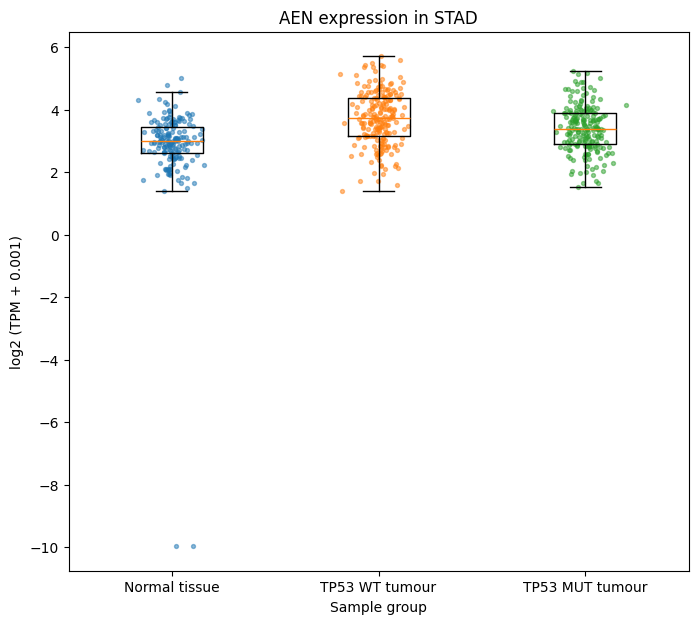

In [58]:
plot_data = expr[expr["cancer_type"] == CANCER_TYPE] # Keep al STAD data (tumour and normal)

# select normal rows
normal_values = plot_data[plot_data["group"] == "normal"]["log2_tpm"].dropna() # take expression measurements / drop missing rows

# Select wild-type rows (tumour group and wild-type tp53 status) and mutant rows (tumour group and MUT tp53 status)
wt_values = plot_data[(plot_data["group"] == "tumour") & (plot_data["tp53_status"] == "WT")]["log2_tpm"].dropna() # take expression measurements / drop missing rows
mut_values = plot_data[(plot_data["group"] == "tumour") & (plot_data["tp53_status"] == "MUT")]["log2_tpm"].dropna() # take expression measurements / drop missing rows

groups = [normal_values, wt_values, mut_values] # Create a list with the three variables

# Create our figure (single panel)
fig, ax = plt.subplots(figsize=(8, 7))
ax.boxplot(groups, showfliers = False) # Create a box plot removing any outliers.




# Create scatter
for position, values in enumerate(groups, start=1):
    x = np.random.normal(position, 0.06, len(values)) # Create a random coordinate for each group (prevent stacking)
    ax.scatter(x, values, s=8, alpha=0.5)

ax.set_xticks([1, 2, 3], labels=["Normal tissue", "TP53 WT tumour", "TP53 MUT tumour"])

ax.set_xlabel("Sample group")
ax.set_ylabel("log2 (TPM + 0.001)")
ax.set_title(f"{GENE} expression in {CANCER_TYPE}")



In [59]:
def plot_comparison(expr, gene, cancer_type):
    """Plotting gene expression between the normal tissue and TP53 tumours (wildtype and mutant).

    Args:
        expr: Tidied DataFrame expression for a gene.
        gene: Gene used (in this case is AEN).
        cancer_type: The cancer type selected (in this case is STAD).

    Returns:
        fig: A matplotlib figure with one panel where x-axis shows normal or tumour types and
        y-axis shows log2 (TPM + 0.001) representing expression.

    Missing expression values are excluded.
    Missing labelled tumours ("MUT" or "WT") are excluded.

    """


    plot_data = expr[expr["cancer_type"] == cancer_type] # Keep data for the cancer type (tumour and normal)

    # select normal rows
    normal_values = plot_data[plot_data["group"] == "normal"]["log2_tpm"].dropna() # take expression measurements / drop missing rows

    # Select wild-type rows (tumour group and wild-type tp53 status) and mutant rows (tumour group and MUT tp53 status)
    wt_values = plot_data[(plot_data["group"] == "tumour") & (plot_data["tp53_status"] == "WT")]["log2_tpm"].dropna() # take expression measurements / drop missing rows
    mut_values = plot_data[(plot_data["group"] == "tumour") & (plot_data["tp53_status"] == "MUT")]["log2_tpm"].dropna() # take expression measurements / drop missing rows

    groups = [normal_values, wt_values, mut_values] # Create a list with the three variables

    # Create our figure (single panel)
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.boxplot(groups, showfliers=False) # Hide boxplot outlier markers and will scatter show all samples




    # Create scatter
    for position, values in enumerate(groups, start=1):
        x = np.random.normal(position, 0.06, len(values)) # Create a random coordinate for each group (prevent stacking)
        ax.scatter(x, values, s=8, alpha=0.5)

    ax.set_xticks([1, 2, 3], labels=["Normal tissue", "TP53 WT tumour", "TP53 MUT tumour"]) # Giving individual groups their label

    ax.set_xlabel("Sample group") # set x axis label
    ax.set_ylabel("log2 (TPM + 0.001)") # set y axis label
    ax.set_title(f"{gene} expression in {cancer_type}") # set plot title

    return fig


✅ returns a matplotlib Figure
✅ has exactly one set of axes
✅ has three groups on the x-axis
✅ the y-axis is labelled
✅ the y-label mentions the log2 scale
✅ the title names the gene

6 of 6 checks passed


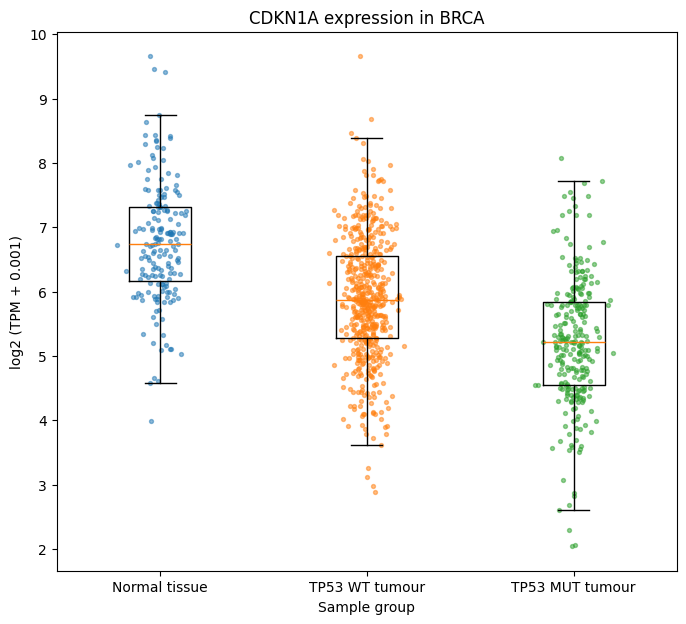

In [60]:
# CHECK - structure only. How it *looks* is marked by eye.
fig_check = plot_comparison(example, "CDKN1A", "BRCA")

run_checks({
    "returns a matplotlib Figure":
        lambda: isinstance(fig_check, plt.Figure),
    "has exactly one set of axes":
        lambda: len(fig_check.axes) == 1,
    "has three groups on the x-axis":
        lambda: len(fig_check.axes[0].get_xticks()) == 3,
    "the y-axis is labelled":
        lambda: bool(fig_check.axes[0].get_ylabel().strip()),
    "the y-label mentions the log2 scale":
        lambda: "log2" in fig_check.axes[0].get_ylabel().lower(),
    "the title names the gene":
        lambda: "CDKN1A" in fig_check.axes[0].get_title(),
})

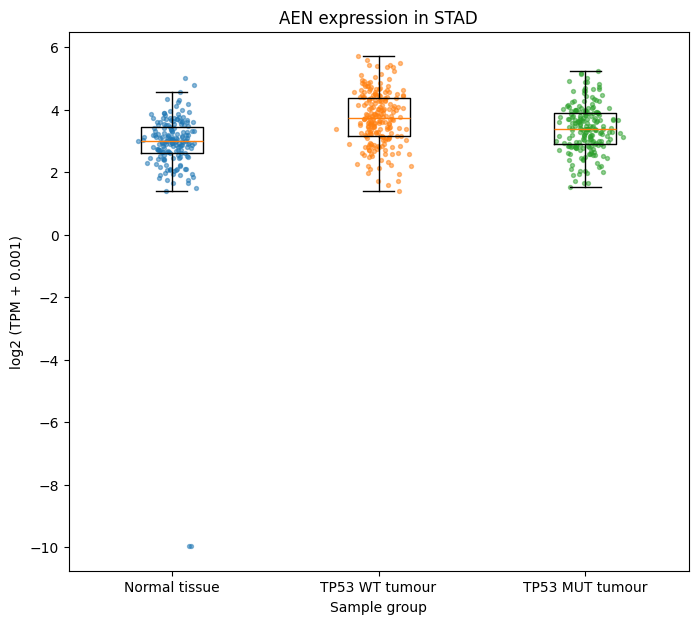

In [61]:
fig = plot_comparison(expr, GENE, CANCER_TYPE)

---

## Pulling it together — `run_analysis`

One function that runs the whole analysis and returns the answer.
**Each key is marked separately**, so a key you cannot produce costs you
that key and nothing else.

```python
run_analysis(expression_path, gene, cancer_type)
```

**Takes** `expression_path`, the path to the tidy expression CSV;
`gene`; and `cancer_type`.

**Returns**:

```python
{"gene": str, "cancer_type": str, "n_samples": int,
 "landscape_top": str,          # cancer type with the highest median
 "tumour_vs_normal": {...},     # a compare_groups dict
 "tp53": {...},                 # a compare_groups dict
 "verdict": "down" | "up" | "no change"}
```

`verdict` follows from the TP53 comparison: not significant →
`"no change"`; `difference` below zero → `"down"`; above zero → `"up"`.

Note it takes **only** the expression file. Notebook 01 is not part of
this — it stands on its own, and nothing here can be blocked by it.

In [66]:
expression_path = MY_EXPRESSION
gene = GENE
cancer_type = CANCER_TYPE

expr = pd.read_csv(expression_path) # load csv from expression_path

# "gene" and "cancer_type" has been supplied already as a function input

# "n_samples"
cohort = expr[expr["cancer_type"] == cancer_type] # cancer_type equal to caner_type is what is analysed
n_samples = len(cohort) # Count of rows is the number of samples

# "landscape_top"
landscape = expression_landscape(expr) # Call expression_landscape with whole expr table
landscape_top = str(landscape["cancer_type"][0]) # Take first value of landscape in cancer_type column (the highest median expression).

# "tumour_vs_normal"
tumour_vs_normal = compare_groups(cohort, "group", "tumour", "normal") # Create a dictionary. One table seperated by labels

# "tp53"
tumours = cohort[cohort["group"] == "tumour"] # filter to tumours only
tp53 = compare_groups(tumours, "tp53_status", "MUT", "WT") # Create a dictionary. One table seperated by labels

# Verdict
if tp53["significant"] is False: # no statistically significanct difference
    verdict = "no change"
elif tp53["difference"] < 0: # if differnce is less than 0 verdict is "down"
    verdict = "down"
elif tp53["difference"] > 0:  # if difference is more than 0 verdict is "up"
    verdict = "up"
else:
    verdict = "no change" # else there isn't a change in significance / direction


summary = {"gene": gene, "cancer_type": cancer_type, "n_samples": n_samples, "landscape_top": landscape_top,
           "tumour_vs_normal": tumour_vs_normal, "tp53": tp53, "verdict": verdict}



In [72]:
def run_analysis(expression_path, gene, cancer_type):
    """Expression analysis of the chosen gene and cancer type.

    Args:
        expression_path: The tidy expression of the csv file.
        gene: The gene selected.
        cancer_type: The cancer type selected.

    Returns:
        summary(dict): gene (str), cancer_type (str), n_samples (int -> all samples for the selected cancer type),
        landscape_top (str -> cancer type with highest median), tumour_vs_normal (dict),
        tp53 (dict), and verdict (str: "down", "up" or "no change").

    Comparison dictionaries are generated by compare_groups.
    Verdict takes values from TP53 significance and MUT - WT median difference

    """

    expr = pd.read_csv(expression_path) # load csv from expression_path

    # "gene" and "cancer_type" has been supplied already as a function input

    # "n_samples"
    cohort = expr[expr["cancer_type"] == cancer_type] # cancer_type equal to caner_type is what is analysed
    n_samples = len(cohort) # Count of rows is the number of samples

    # "landscape_top"
    landscape = expression_landscape(expr) # Call expression_landscape with whole expr table
    landscape_top = str(landscape["cancer_type"][0]) # Take first value of landscape in cancer_type column (the highest median expression).

    # "tumour_vs_normal"
    tumour_vs_normal = compare_groups(cohort, "group", "tumour", "normal") # Create a dictionary. One table seperated by labels

    # "tp53"
    tumours = cohort[cohort["group"] == "tumour"] # filter to tumours only
    tp53 = compare_groups(tumours, "tp53_status", "MUT", "WT") # Create a dictionary. One table seperated by labels

    # Verdict
    if tp53["significant"] is False: # no statistically significanct difference
        verdict = "no change"
    elif tp53["difference"] < 0: # if differnce is less than 0 verdict is "down"
        verdict = "down"
    elif tp53["difference"] > 0:  # if difference is more than 0 verdict is "up"
        verdict = "up"
    else:
        verdict = "no change" # else there isn't a change in significance / direction

    # Summary creating
    summary = {"gene": gene, "cancer_type": cancer_type, "n_samples": n_samples, "landscape_top": landscape_top,
              "tumour_vs_normal": tumour_vs_normal, "tp53": tp53, "verdict": verdict}

    return summary


In [68]:
# CHECK - against the worked example
result_check = run_analysis(EXAMPLE_EXPRESSION, "CDKN1A", "BRCA")

run_checks({
    "returns a dict with exactly the seven keys":
        lambda: set(result_check) == {"gene", "cancer_type", "n_samples",
                                       "landscape_top", "tumour_vs_normal",
                                       "tp53", "verdict"},
    "gene and cancer_type are passed through":
        lambda: (result_check["gene"] == "CDKN1A"
                 and result_check["cancer_type"] == "BRCA"),
    "landscape_top matches (PAAD)":
        lambda: result_check["landscape_top"] == "PAAD",
    "the nested comparisons are dicts":
        lambda: all(isinstance(result_check[k], dict)
                    for k in ("tumour_vs_normal", "tp53")),
    "verdict is one of the three allowed words":
        lambda: result_check["verdict"] in {"down", "up", "no change"},
    "verdict for CDKN1A in BRCA is 'down'":
        lambda: result_check["verdict"] == "down",
})

✅ returns a dict with exactly the seven keys
✅ gene and cancer_type are passed through
✅ landscape_top matches (PAAD)
✅ the nested comparisons are dicts
✅ verdict is one of the three allowed words
✅ verdict for CDKN1A in BRCA is 'down'

6 of 6 checks passed


In [71]:
result = run_analysis(MY_EXPRESSION, GENE, CANCER_TYPE)
result

{'gene': 'AEN',
 'cancer_type': 'STAD',
 'n_samples': 588,
 'landscape_top': 'COAD',
 'tumour_vs_normal': {'n_a': 414,
  'n_b': 174,
  'median_a': 3.56995,
  'median_b': 2.99385,
  'difference': 0.5760999999999998,
  'p_value': 9.258557773147027e-15,
  'significant': True},
 'tp53': {'n_a': 200,
  'n_b': 210,
  'median_a': 3.3903499999999998,
  'median_b': 3.71985,
  'difference': -0.32950000000000035,
  'p_value': 3.535464682428e-05,
  'significant': True},
 'verdict': 'down'}

---

## Your answer, in one sentence

Write it the way you would say it to another biologist. Direction, size,
p-value, and what it means.

> *Your one-sentence answer here.*

---

## Your GitHub repository

Paste the link to your project repository below. It is marked: at
least 5 meaningful commits, and a README — see *The 15 GitHub marks* in
`00_start_here`.

**My repository:** *paste your link here*